# Titanic Dataset Analysis
## Data Science with Python Internship – Task 2

**Objective:** Clean the Titanic passenger dataset, analyze survival patterns, and visualize the results using Pandas, Seaborn, and Matplotlib.

### Dataset
Download `train.csv` from the [Kaggle Titanic competition](https://www.kaggle.com/competitions/titanic/data). In Google Colab, run the upload cell below and select the downloaded `train.csv` file.

**Libraries used:** Pandas, Seaborn, Matplotlib (no NumPy required).

In [2]:
# Step 1: Import required libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


## Step 2: Load the Titanic dataset

Run this cell in Google Colab and upload the Kaggle file named `train.csv`.

In [3]:
# Google Colab upload
from google.colab import files
uploaded = files.upload()

# Read the uploaded CSV file
df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Saving train.csv to train.csv
Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Step 3: Explore the dataset

Check the first rows, column names, data types, and missing values before cleaning.

In [4]:
# Preview and inspect the data
display(df.head())
print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0


## Step 4: Clean the data

- Fill missing `Age` values with the median age.
- Fill missing `Embarked` values with the most frequent port.
- Drop `Cabin` because many entries are missing.
- Remove duplicate rows, if any.

The original dataset is kept unchanged in `df_original` for reference.

In [5]:

# Keep a copy of the original data
df_original = df.copy()

# Fill missing Age values with the median
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing Embarked values with the mode
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Drop Cabin column
df = df.drop(columns=["Cabin"])

# Remove duplicate rows
df = df.drop_duplicates()

print("Data cleaning completed!")

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())


Data cleaning completed!

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [6]:
print(df.head())
print("Dataset loaded successfully!")

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Embarked  
0      0         A/5 21171   7.2500        S  
1      0          PC 17599  71.2833        C  
2      0  STON/O2. 3101282   7.9250        S  
3      0            113803  53.1000        S  
4      0            373450   8.0500        S  
Dataset loaded successfully!


## Step 5: Basic data analysis

The `Survived` column uses:
- `0` = Did not survive
- `1` = Survived

Calculate the overall number and percentage of survivors.

In [7]:
survivor_counts = df["Survived"].value_counts().sort_index()
survival_rate = df["Survived"].mean() * 100

print("Passenger survival counts:")
print("Did not survive:", survivor_counts.get(0, 0))
print("Survived:", survivor_counts.get(1, 0))
print("Overall survival rate: {:.2f}%".format(survival_rate))

Passenger survival counts:
Did not survive: 549
Survived: 342
Overall survival rate: 38.38%


## Step 6: Who survived more – males or females?

Calculate the survival rate for each gender. A higher percentage means a higher proportion of that group survived.

In [9]:
gender_survival = df.groupby("Sex")["Survived"].mean() * 100

print("Survival rate by gender (%):")
print(gender_survival.round(2))

if gender_survival["female"] > gender_survival["male"]:
    print("Female passengers had a higher survival rate.")
else:
    print("Male passengers had a higher survival rate.")

Survival rate by gender (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64
Female passengers had a higher survival rate.


## Step 7: Did passenger class affect survival chances?

Passenger class:
- 1 = First class
- 2 = Second class
- 3 = Third class

In [10]:
class_survival = df.groupby("Pclass")["Survived"].mean() * 100

print("Survival rate by passenger class (%):")
print(class_survival.round(2))

highest_class = class_survival.idxmax()

print("Passenger class", highest_class,
      "had the highest survival rate.")

Survival rate by passenger class (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64
Passenger class 1 had the highest survival rate.


## Step 8: What was the survival rate by age group?

Group passenger ages into child, young adult, adult, and senior categories. Then calculate the survival rate in each group.

In [11]:
age_bins = [0, 12, 18, 35, 60, 100]

age_labels = [
    "Child (0-12)",
    "Teen (13-18)",
    "Young Adult (19-35)",
    "Adult (36-60)",
    "Senior (61+)"
]

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

age_group_survival = df.groupby(
    "AgeGroup", observed=False
)["Survived"].mean() * 100

print("Survival rate by age group (%):")
print(age_group_survival.round(2))

Survival rate by age group (%):
AgeGroup
Child (0-12)           57.97
Teen (13-18)           42.86
Young Adult (19-35)    35.33
Adult (36-60)          40.00
Senior (61+)           22.73
Name: Survived, dtype: float64


## Step 9: Visualize survival by gender

The bar chart shows the average survival rate for male and female passengers.

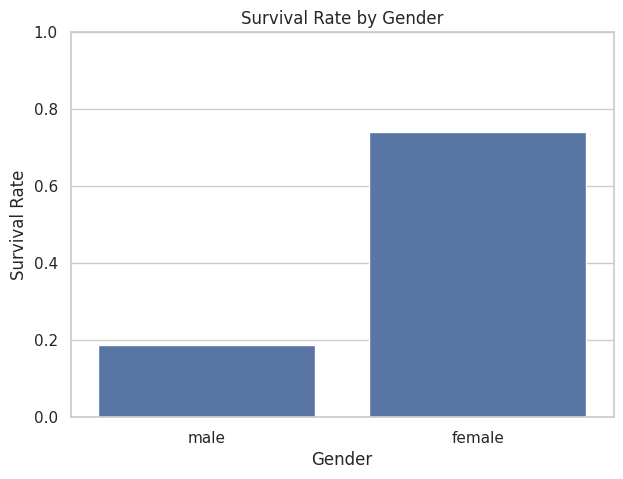

In [12]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Sex",
    y="Survived",
    errorbar=None
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)

plt.show()

## Step 10: Visualize survival by passenger class

The bar chart compares the average survival rate across first, second, and third class.

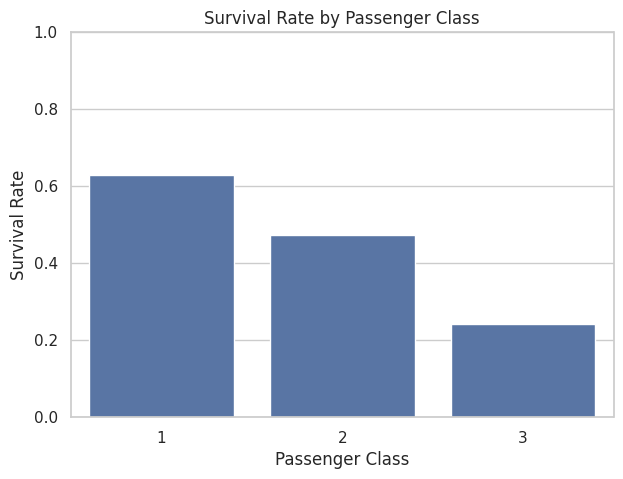

In [13]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Pclass",
    y="Survived",
    errorbar=None,
    order=[1, 2, 3]
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)

plt.show()

## Step 11: Histogram of passenger ages

The histogram displays the distribution of passenger ages after filling missing age values.

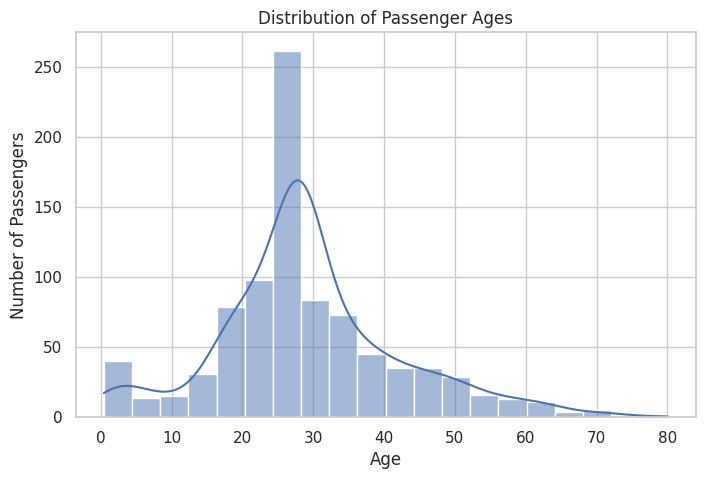

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

## Step 12: Final findings and conclusion

The following cell prints the main findings calculated from the dataset. Use the actual output from your run in your internship explanation.

In [15]:
print("TITANIC DATASET ANALYSIS")
print("------------------------")

print("Overall survival rate:",
      round(survival_rate, 2), "%")

print("\nSurvival by gender:")
print(gender_survival.round(2))

print("\nSurvival by class:")
print(class_survival.round(2))

print("\nSurvival by age group:")
print(age_group_survival.round(2))

print("\nConclusion:")
print("The analysis shows differences in survival")
print("based on gender, passenger class and age.")
print("Data visualization helps us understand")
print("these survival patterns.")

TITANIC DATASET ANALYSIS
------------------------
Overall survival rate: 38.38 %

Survival by gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

Survival by class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

Survival by age group:
AgeGroup
Child (0-12)           57.97
Teen (13-18)           42.86
Young Adult (19-35)    35.33
Adult (36-60)          40.00
Senior (61+)           22.73
Name: Survived, dtype: float64

Conclusion:
The analysis shows differences in survival
based on gender, passenger class and age.
Data visualization helps us understand
these survival patterns.


---
## Submission checklist

- [ ] Uploaded and loaded the Kaggle `train.csv` file.
- [ ] Checked missing values and cleaned the dataset.
- [ ] Calculated survival by gender, passenger class, and age group.
- [ ] Created both bar charts and the age histogram.
- [ ] Ran every cell from top to bottom and checked that outputs/graphs appear.
- [ ] Saved the completed notebook as `.ipynb`.

**Note:** The numerical results are generated when you run the notebook on the Kaggle dataset. Do not submit a notebook with missing outputs; run all cells first.